In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

In [2]:
data = pd.read_csv("Datasets/age_salary_hours.csv")

In [3]:
# Count education categories
education_counts = data["Education"].value_counts()
 
# Calculate percentages
education_percentages = (
education_counts / education_counts.sum() * 100
)
education_percentages = education_percentages.reindex(
[
"Associate's degree",
"No diploma",
"Attended college, no degree",
"Bachelor's degree or higher",
"High school diploma"
]
)

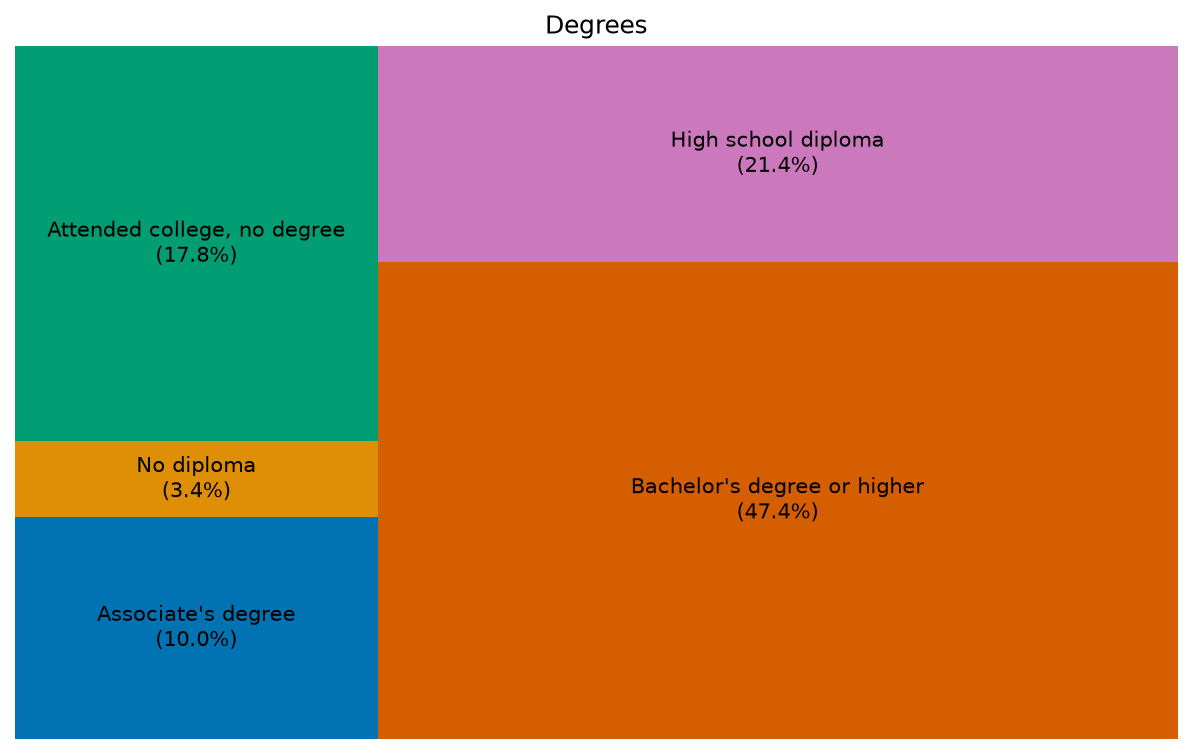

In [4]:
# Create labels
labels = [
f"{edu}\n({pct:.1f}%)"
for edu, pct in education_percentages.items()
]
 
# Colorblind-friendly palette
colors = sns.color_palette("colorblind", len(labels))
 
# Create figure
plt.figure(figsize=(10, 6), dpi=150)
 
# Create treemap
squarify.plot(
sizes=education_percentages.values,
label=labels,
color=colors
)
 
plt.axis("off")
plt.title("Degrees")
 
plt.show()

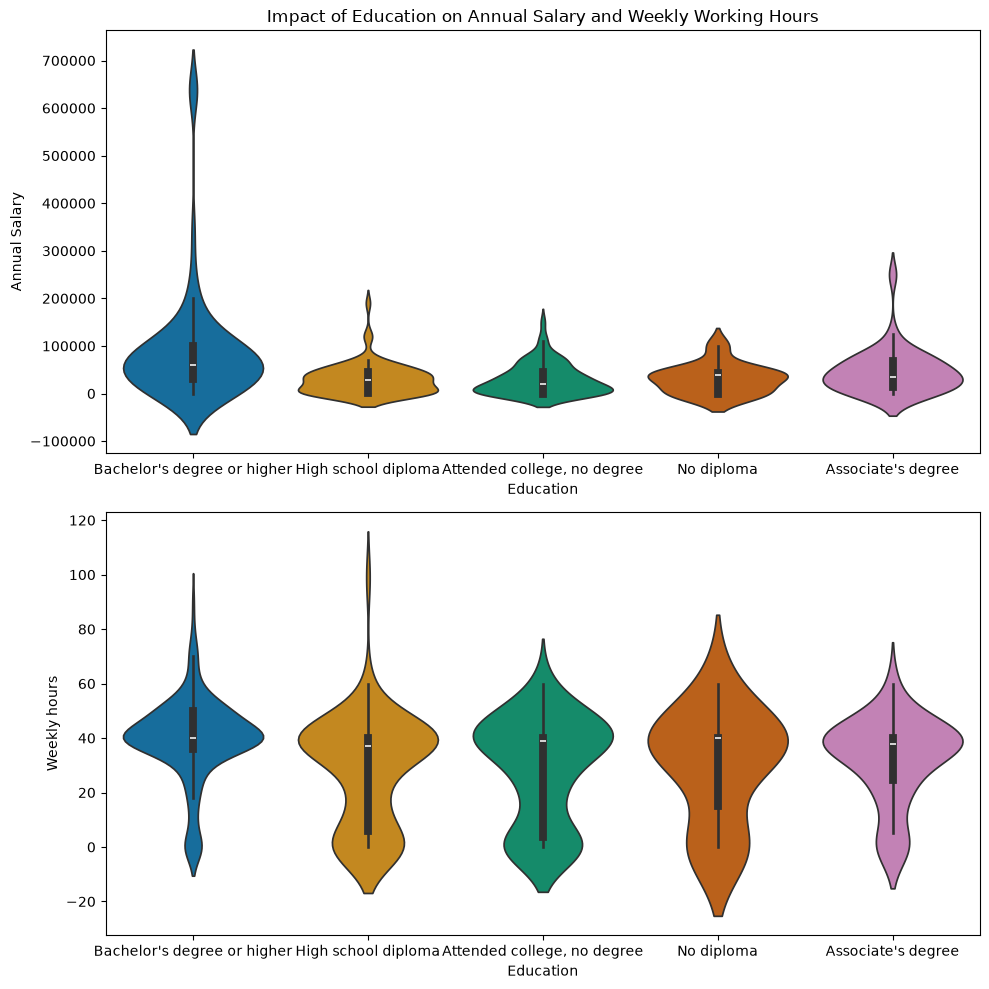

In [5]:
# Exclude pensioners
data = data[data["Age"] < 65]
 
# Colorblind-friendly palette
palette = sns.color_palette("colorblind", 5)
 
# Create subplots
fig, axes = plt.subplots(
2,
1,
figsize=(10, 10)
)
 
# Annual Salary
sns.violinplot(
data=data,
x="Education",
y="Annual Salary",
hue="Education",
palette=palette,
legend=False,
ax=axes[0]
)
 
axes[0].set_title(
"Impact of Education on Annual Salary and Weekly Working Hours"
)
axes[0].set_xlabel("Education")
axes[0].set_ylabel("Annual Salary")
 
# Weekly hours
sns.violinplot(
data=data,
x="Education",
y="Weekly hours",
hue="Education",
palette=palette,
legend=False,
ax=axes[1]
)
 
axes[1].set_xlabel("Education")
axes[1].set_ylabel("Weekly hours")
 
plt.tight_layout()
 
plt.show()